# Лабораторная работа 5 (В26)
## Введение
**Название:** многомерная регрессия

**Цель:** изучение принципов решения задачи многомерной регрессии с использованием методов машинного обучения.

**Описание показателей:**
- Employees - общее количество сотрудников на заводе
- Machine_Age - средний возраст оборудования в годах
- Overtime - среднее количество сверхурочных часов в месяц
- Inspections - количество проверок техники безопасности в год
- Safety_Budget - бюджет, выделенный на средства защиты
- Accidents - общее количество несчастных случаев в год

## 1. Подготовительный этап
## 1.1 Импортируем библиотеки и загружаем данные

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('factory_accidents.csv')
df.head()

,Accidents,Employees,Safety_Hours,Machine_Age,Overtime,Inspections,Safety_Budget
0,2,269,27.3,18.6,7.9,1,32.17
1,6,242,17.2,6.2,32.3,2,24.36
2,3,250,11.4,3.4,11.5,2,18.49
3,3,234,28.0,8.6,13.5,1,20.71
4,1,248,38.4,1.7,22.8,1,26.83


In [2]:
# выведем размер данных
print('Размер данных:', df.shape)

Размер данных: (1269, 7)


### 1.2 Проанализируем целевую переменную

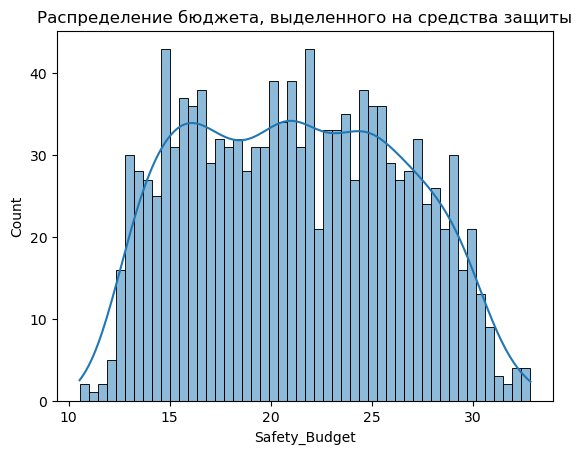

In [3]:
sns.histplot(df['Safety_Budget'], bins = 50, kde = True)
plt.title('Распределение бюджета, выделенного на средства защиты')
plt.show()

По графику видно, что популярны финансирования безопасности от 12 до 31 тысячи. По сути это область всего датасета, кроме самых краёв. Целевая переменная сбалансирована, данные удалять не требуется.
### 1.3 Получим информацию о датасете

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1269 entries, 0 to 1268
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Accidents      1269 non-null   int64  
 1   Employees      1269 non-null   int64  
 2   Safety_Hours   1269 non-null   float64
 3   Machine_Age    1269 non-null   float64
 4   Overtime       1269 non-null   float64
 5   Inspections    1269 non-null   int64  
 6   Safety_Budget  1269 non-null   float64
dtypes: float64(4), int64(3)
memory usage: 69.5 KB


Категориальных значений нет, все значения числовые.
### 1.4 Проверим на пустые значения

In [5]:
df.isnull().sum()

Accidents        0
Employees        0
Safety_Hours     0
Machine_Age      0
Overtime         0
Inspections      0
Safety_Budget    0
dtype: int64

Пустые значения отсутствуют, прекрасно!
## 2. Машинное обучение
### 2.1 Разделяем данные на признаки и целевую переменную

In [6]:
y = df['Safety_Budget']
X = df.drop('Safety_Budget', axis=1)

# проверим тип данных
print(type(X), type(y))

# проверим признаки
X.head()

<class 'pandas.core.frame.DataFrame'> <class 'pandas.core.series.Series'>


,Accidents,Employees,Safety_Hours,Machine_Age,Overtime,Inspections
0,2,269,27.3,18.6,7.9,1
1,6,242,17.2,6.2,32.3,2
2,3,250,11.4,3.4,11.5,2
3,3,234,28.0,8.6,13.5,1
4,1,248,38.4,1.7,22.8,1


### 2.2 Разделяем данные на обучающую и тестовую выборки
Используем соотношение 75% для обучения и 25% для проверки

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

### 2.3 Применяем нормализацию для численной устойчивости

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.4 Обучаем модель линейной регрессии

In [11]:
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train_scaled, y_train)
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### 2.5 Делаем прогноз на основе данных тестирования

In [12]:
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

# выведем первые 5 значений
y_pred_test[:5]

array([17.59585473, 22.10214743, 22.84450171, 23.85031057, 21.31320989])

## 3. Работа с результатами
### 3.1 Оценка качества

In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# напишем функцию оценкм
def evaluate_model(y_true, y_pred, set_name = ""):
    mse = mean_squared_error(y_true, y_pred)
    print(f"___ {set_name} ___")
    print(f"MSE: {mse:.2f}")
    print(f"RMSE: {np.sqrt(mse):.2f}")
    print(f"MAE: {mean_absolute_error(y_true, y_pred):.2f}")
    print(f"R2: {r2_score(y_true, y_pred):.2f}")
    print()

evaluate_model(y_train, y_pred_train, "Train set")
evaluate_model(y_test, y_pred_test, "Test set")

___ Train set ___
MSE: 23.96
RMSE: 4.89
MAE: 4.20
R2: 0.07

___ Test set ___
MSE: 26.23
RMSE: 5.12
MAE: 4.47
R2: 0.04



Можно заметить, что модель объясняет только 4% данных, что весьма мало и печально
### 3.2 Итоговое уравнение

In [14]:
print("Коэфиценты: ", model.coef_)
print("Свободный член: ", model.intercept_)

Коэфиценты:  [-0.97988381  1.13485786 -0.19625727  0.40100957  0.55983655 -0.01136696]
Свободный член:  21.379432176656156


### 3.3 Оценим влияние признаков на целевую переменную

In [15]:
from sklearn.preprocessing import LabelEncoder
labelencoder_o = LabelEncoder()
df['Safety_Budget'] = labelencoder_o.fit_transform(df['Safety_Budget'])
df

,Accidents,Employees,Safety_Hours,Machine_Age,Overtime,Inspections,Safety_Budget
0,2,269,27.3,18.6,7.9,1,900
1,6,242,17.2,6.2,32.3,2,615
2,3,250,11.4,3.4,11.5,2,318
3,3,234,28.0,8.6,13.5,1,427
4,1,248,38.4,1.7,22.8,1,732
...,...,...,...,...,...,...,...
1264,8,255,12.2,4.0,16.9,1,668
1265,0,267,9.3,0.4,12.1,4,562
1266,9,249,23.3,8.4,19.8,2,565
1267,3,270,22.2,5.3,12.6,1,56


In [16]:
df.corr()

,Accidents,Employees,Safety_Hours,Machine_Age,Overtime,Inspections,Safety_Budget
Accidents,1.000000,0.000066,-0.393053,0.366721,0.415531,-0.240751,-0.106527
Employees,0.000066,1.000000,0.018041,0.014329,-0.035888,-0.046051,0.202029
Safety_Hours,-0.393053,0.018041,1.000000,-0.029992,0.012675,-0.029673,0.019670
Machine_Age,0.366721,0.014329,-0.029992,1.000000,-0.034026,0.032996,-0.012237
Overtime,0.415531,-0.035888,0.012675,-0.034026,1.000000,0.032461,0.033024
Inspections,-0.240751,-0.046051,-0.029673,0.032996,0.032461,1.000000,0.035340
Safety_Budget,-0.106527,0.202029,0.019670,-0.012237,0.033024,0.035340,1.000000


Исходя из таблицы корреляции можно сказать, что наибольшее влияние на бюджет имеет количество сотрудников на заводе (20%). Также из интересного можно заметить, что на количество событий большое влияение оказывают почи все показатели (за исключением количества рабочиз) и что количество инспекций  влияет с отрицательным коэфицентом (а значит чем больше инспекций, тем меньше инцидентов).
### 3.4 Остатки регрессии
Нарисуем график

Text(0.5, 1.0, 'Остатки vs предсказания')

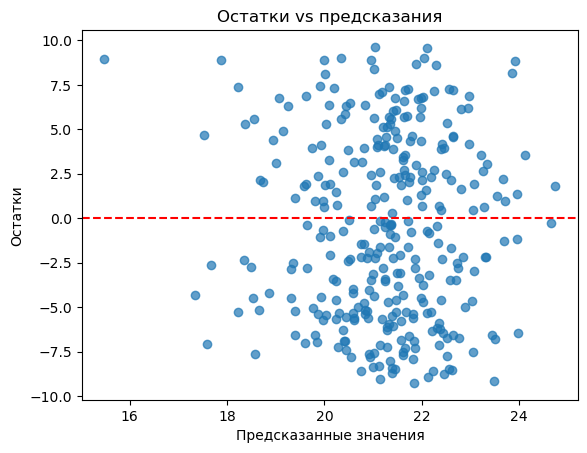

In [17]:
residuals = y_test - y_pred_test
plt.scatter(y_pred_test, residuals, alpha = 0.7)
plt.axhline(y = 0, color = 'r', linestyle = '--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Остатки vs предсказания')

Точки хаотично разбросаны вокруг прямой, явных фигур не видно - это отлично. Построим диаграмму распределения остатков:

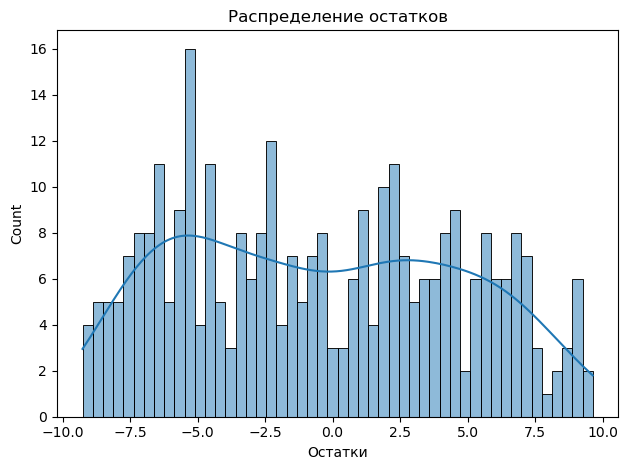

In [18]:
sns.histplot(residuals, bins = 50, kde = True)
plt.xlabel('Остатки')
plt.title('Распределение остатков')
plt.tight_layout()
plt.show()

Остатки распределены более-менее равномерно.

Лабораторная работа выполнена.